# 01 · Conversión de anotaciones SoccerNet a keypoints YOLO

**Objetivo:** transformar las anotaciones de líneas de SoccerNet-Calibration en un conjunto fijo de 24 keypoints del campo en formato YOLOv8-pose, calculando las intersecciones entre líneas.

**Contexto:** SoccerNet no anota keypoints directamente, sino las líneas del campo como listas de puntos. Para la homografía necesitamos puntos concretos con correspondencia conocida en el campo real (esquinas de áreas, córners, etc.). Estos puntos se obtienen calculando las intersecciones entre las líneas anotadas. Los keypoints no visibles en un frame se marcan con visibilidad 0, formato que YOLOv8-pose soporta de forma nativa.

**Entrada:** dataset SoccerNet-Calibration descargado en `data/soccernet/`.

**Salida:** dataset en formato YOLOv8-pose en `data/soccernet_yolo/`.#%% md
# 01 · Conversión de anotaciones SoccerNet a keypoints YOLO

**Objetivo:** transformar las anotaciones de líneas de SoccerNet-Calibration en un conjunto fijo de 24 keypoints del campo en formato YOLOv8-pose, calculando las intersecciones entre líneas.

**Contexto:** SoccerNet no anota keypoints directamente, sino las líneas del campo como listas de puntos. Para la homografía necesitamos puntos concretos con correspondencia conocida en el campo real (esquinas de áreas, córners, etc.). Estos puntos se obtienen calculando las intersecciones entre las líneas anotadas. Los keypoints no visibles en un frame se marcan con visibilidad 0, formato que YOLOv8-pose soporta de forma nativa.

**Entrada:** dataset SoccerNet-Calibration descargado en `data/soccernet/`.

**Salida:** dataset en formato YOLOv8-pose en `data/soccernet_yolo/`.

## 1. Definición de los keypoints del campo

Se define el conjunto de 24 keypoints con su correspondencia en el campo real (coordenadas en metros, campo de 105×68). Todos los puntos están en el plano del césped, incluidas las bases de los postes, para que la homografía sea válida.

In [1]:
from pathlib import Path

REPO_ROOT = Path("../..").resolve()
SOCCERNET_DIR = REPO_ROOT / "data" / "soccernet" / "calibration-2023"
OUTPUT_DIR = REPO_ROOT / "data" / "soccernet_yolo"

# Dimensiones oficiales del campo (metros)
FIELD_LENGTH = 105.0
FIELD_WIDTH = 68.0

# Definición de los 24 keypoints: nombre y coordenadas reales (x, y) en metros
KEYPOINTS = [
    ("corner_inf_izq",        (0.0,    0.0)),     # 0
    ("corner_sup_izq",        (0.0,    68.0)),    # 1
    ("corner_inf_der",        (105.0,  0.0)),     # 2
    ("corner_sup_der",        (105.0,  68.0)),    # 3
    ("area_grande_izq_inf",   (16.5,   13.84)),   # 4
    ("area_grande_izq_sup",   (16.5,   54.16)),   # 5
    ("area_grande_der_inf",   (88.5,   13.84)),   # 6
    ("area_grande_der_sup",   (88.5,   54.16)),   # 7
    ("area_peq_izq_inf",      (5.5,    24.84)),   # 8
    ("area_peq_izq_sup",      (5.5,    43.16)),   # 9
    ("area_peq_der_inf",      (99.5,   24.84)),   # 10
    ("area_peq_der_sup",      (99.5,   43.16)),   # 11
    ("penalti_izq",           (11.0,   34.0)),    # 12
    ("penalti_der",           (94.0,   34.0)),    # 13
    ("centro",                (52.5,   34.0)),    # 14
    ("media_inf",             (52.5,   0.0)),     # 15
    ("media_sup",             (52.5,   68.0)),    # 16
    ("fondo_izq_area_inf",    (0.0,    13.84)),   # 17
    ("fondo_izq_area_sup",    (0.0,    54.16)),   # 18
    ("fondo_der_area_inf",    (105.0,  13.84)),   # 19
    ("poste_izq_inf",         (0.0,    30.34)),   # 20
    ("poste_izq_sup",         (0.0,    37.66)),   # 21
    ("poste_der_inf",         (105.0,  30.34)),   # 22
    ("poste_der_sup",         (105.0,  37.66)),   # 23
]

N_KEYPOINTS = len(KEYPOINTS)
print(f"Total de keypoints definidos: {N_KEYPOINTS}")
for i, (nombre, (x, y)) in enumerate(KEYPOINTS):
    print(f"  {i:2}. {nombre:<22} ({x}, {y})")

Total de keypoints definidos: 24
   0. corner_inf_izq         (0.0, 0.0)
   1. corner_sup_izq         (0.0, 68.0)
   2. corner_inf_der         (105.0, 0.0)
   3. corner_sup_der         (105.0, 68.0)
   4. area_grande_izq_inf    (16.5, 13.84)
   5. area_grande_izq_sup    (16.5, 54.16)
   6. area_grande_der_inf    (88.5, 13.84)
   7. area_grande_der_sup    (88.5, 54.16)
   8. area_peq_izq_inf       (5.5, 24.84)
   9. area_peq_izq_sup       (5.5, 43.16)
  10. area_peq_der_inf       (99.5, 24.84)
  11. area_peq_der_sup       (99.5, 43.16)
  12. penalti_izq            (11.0, 34.0)
  13. penalti_der            (94.0, 34.0)
  14. centro                 (52.5, 34.0)
  15. media_inf              (52.5, 0.0)
  16. media_sup              (52.5, 68.0)
  17. fondo_izq_area_inf     (0.0, 13.84)
  18. fondo_izq_area_sup     (0.0, 54.16)
  19. fondo_der_area_inf     (105.0, 13.84)
  20. poste_izq_inf          (0.0, 30.34)
  21. poste_izq_sup          (0.0, 37.66)
  22. poste_der_inf          (105.0, 3

## 2. Funciones geométricas auxiliares

Para obtener cada keypoint se calcula la intersección entre dos líneas del campo. Estas funciones implementan la geometría necesaria: convertir los puntos de una línea en una recta y calcular la intersección de dos rectas.

In [2]:
import numpy as np

def linea_a_recta(puntos):
    """Dada una lista de puntos (dict x,y), ajusta una recta y devuelve (a, b, c) de ax+by+c=0."""
    if len(puntos) < 2:
        return None
    pts = np.array([[p["x"], p["y"]] for p in puntos])
    # Ajuste por mínimos cuadrados a una recta
    x = pts[:, 0]
    y = pts[:, 1]
    # Usamos el primer y último punto para definir la dirección (robusto para líneas rectas)
    p1 = pts[0]
    p2 = pts[-1]
    # Recta que pasa por p1 y p2: forma ax + by + c = 0
    a = p2[1] - p1[1]
    b = p1[0] - p2[0]
    c = -(a * p1[0] + b * p1[1])
    return (a, b, c)

def interseccion_rectas(recta1, recta2):
    """Calcula la intersección de dos rectas en forma ax+by+c=0. Devuelve (x, y) o None si son paralelas."""
    if recta1 is None or recta2 is None:
        return None
    a1, b1, c1 = recta1
    a2, b2, c2 = recta2
    det = a1 * b2 - a2 * b1
    if abs(det) < 1e-10:
        return None  # rectas paralelas
    x = (b1 * c2 - b2 * c1) / det
    y = (a2 * c1 - a1 * c2) / det
    return (x, y)

## 3. Reglas de cálculo de cada keypoint

Cada keypoint se obtiene de la intersección de dos líneas concretas de SoccerNet, o directamente de un punto anotado. Este diccionario define, para cada keypoint, qué líneas lo generan.

Las líneas de SoccerNet relevantes son, entre otras: `Side line left/right/top/bottom` (bandas y fondos), `Big rect. left/right main/top/bottom` (área grande), `Small rect. ...` (área pequeña), `Middle line` (línea media), `Goal left/right post ...` (postes).

In [3]:
# Para cada keypoint, definimos de qué intersección de líneas sale.
# Formato: índice_keypoint: (linea_A, linea_B)
# Si el keypoint sale de un punto directo de una línea, se maneja aparte.

REGLAS_INTERSECCION = {
    0:  ("Side line left",        "Side line bottom"),       # corner inf izq
    1:  ("Side line left",        "Side line top"),          # corner sup izq
    2:  ("Side line right",       "Side line bottom"),       # corner inf der
    3:  ("Side line right",       "Side line top"),          # corner sup der
    4:  ("Big rect. left main",   "Big rect. left bottom"),  # area grande izq inf
    5:  ("Big rect. left main",   "Big rect. left top"),     # area grande izq sup
    6:  ("Big rect. right main",  "Big rect. right bottom"), # area grande der inf
    7:  ("Big rect. right main",  "Big rect. right top"),    # area grande der sup
    8:  ("Small rect. left main", "Small rect. left bottom"),# area peq izq inf
    9:  ("Small rect. left main", "Small rect. left top"),   # area peq izq sup
    10: ("Small rect. right main","Small rect. right bottom"),# area peq der inf
    11: ("Small rect. right main","Small rect. right top"),  # area peq der sup
    15: ("Middle line",           "Side line bottom"),       # media inf
    16: ("Middle line",           "Side line top"),          # media sup
    17: ("Side line left",        "Big rect. left bottom"),  # fondo izq area inf
    18: ("Side line left",        "Big rect. left top"),     # fondo izq area sup
    19: ("Side line right",       "Big rect. right bottom"), # fondo der area inf
    20: ("Side line left",        "Goal left post left "),   # base poste izq inf
    21: ("Side line left",        "Goal left post right"),   # base poste izq sup
    22: ("Side line right",       "Goal right post right"),  # base poste der inf
    23: ("Side line right",       "Goal right post left"),   # base poste der sup
}

# Los keypoints 12, 13, 14 (penaltis y centro) no salen de intersección directa de líneas rectas.
# El centro (14) se obtiene del punto medio del "Circle central" si existe.
# Los penaltis no están anotados como línea en SoccerNet, se omitirán (visibilidad 0) salvo que se deriven.

print(f"Reglas de intersección definidas para {len(REGLAS_INTERSECCION)} keypoints")
print("Keypoints 12, 13 (penaltis) y 14 (centro) se tratan aparte")

Reglas de intersección definidas para 21 keypoints
Keypoints 12, 13 (penaltis) y 14 (centro) se tratan aparte


## 4. Función de generación de keypoints por frame

Esta función calcula los 24 keypoints de un frame. Para cada uno:
- Si las dos líneas necesarias están presentes, calcula la intersección.
- Si la intersección cae dentro de la imagen [0,1], el keypoint se marca como visible (v=2).
- Si cae fuera o no se pueden calcular las líneas, se marca como no visible (v=0).

El formato de salida sigue el estándar YOLOv8-pose: para cada keypoint, (x, y, v) donde v=0 (no visible) o v=2 (visible).

In [5]:
MARGEN = 0.05  # tolerancia fuera del borde de la imagen

def generar_keypoints_frame(anotacion):
    """Devuelve una lista de 24 tuplas (x, y, v) en coordenadas normalizadas."""
    keypoints = [(0.0, 0.0, 0)] * N_KEYPOINTS  # por defecto, todos no visibles

    for kp_idx, (linea_a, linea_b) in REGLAS_INTERSECCION.items():
        if linea_a in anotacion and linea_b in anotacion:
            recta_a = linea_a_recta(anotacion[linea_a])
            recta_b = linea_a_recta(anotacion[linea_b])
            punto = interseccion_rectas(recta_a, recta_b)
            if punto:
                x, y = punto
                # Validar que cae dentro de la imagen (con margen)
                if -MARGEN <= x <= 1 + MARGEN and -MARGEN <= y <= 1 + MARGEN:
                    # Recortar a [0,1] por si está en el margen
                    x = min(max(x, 0.0), 1.0)
                    y = min(max(y, 0.0), 1.0)
                    keypoints[kp_idx] = (x, y, 2)  # visible

    # Centro del campo (KP 14) desde el círculo central, si existe
    if "Circle central" in anotacion:
        pts = anotacion["Circle central"]
        if len(pts) >= 2:
            cx = sum(p["x"] for p in pts) / len(pts)
            cy = sum(p["y"] for p in pts) / len(pts)
            if 0 <= cx <= 1 and 0 <= cy <= 1:
                keypoints[14] = (cx, cy, 2)

    return keypoints

# Prueba sobre el frame de ejemplo
kps = generar_keypoints_frame(anotacion)
visibles = sum(1 for k in kps if k[2] == 2)
print(f"Keypoints visibles en el frame de ejemplo: {visibles}/{N_KEYPOINTS}\n")
for i, (x, y, v) in enumerate(kps):
    estado = "visible" if v == 2 else "no visible"
    print(f"  KP {i:2} ({KEYPOINTS[i][0]:<22}): ({x:.3f}, {y:.3f}) - {estado}")

Keypoints visibles en el frame de ejemplo: 7/24

  KP  0 (corner_inf_izq        ): (0.000, 0.000) - no visible
  KP  1 (corner_sup_izq        ): (0.921, 0.298) - visible
  KP  2 (corner_inf_der        ): (0.000, 0.000) - no visible
  KP  3 (corner_sup_der        ): (0.000, 0.000) - no visible
  KP  4 (area_grande_izq_inf   ): (0.263, 0.791) - visible
  KP  5 (area_grande_izq_sup   ): (0.000, 0.000) - no visible
  KP  6 (area_grande_der_inf   ): (0.000, 0.000) - no visible
  KP  7 (area_grande_der_sup   ): (0.000, 0.000) - no visible
  KP  8 (area_peq_izq_inf      ): (0.285, 0.567) - visible
  KP  9 (area_peq_izq_sup      ): (0.676, 0.433) - visible
  KP 10 (area_peq_der_inf      ): (0.000, 0.000) - no visible
  KP 11 (area_peq_der_sup      ): (0.000, 0.000) - no visible
  KP 12 (penalti_izq           ): (0.000, 0.000) - no visible
  KP 13 (penalti_der           ): (0.000, 0.000) - no visible
  KP 14 (centro                ): (0.000, 0.000) - no visible
  KP 15 (media_inf             ):

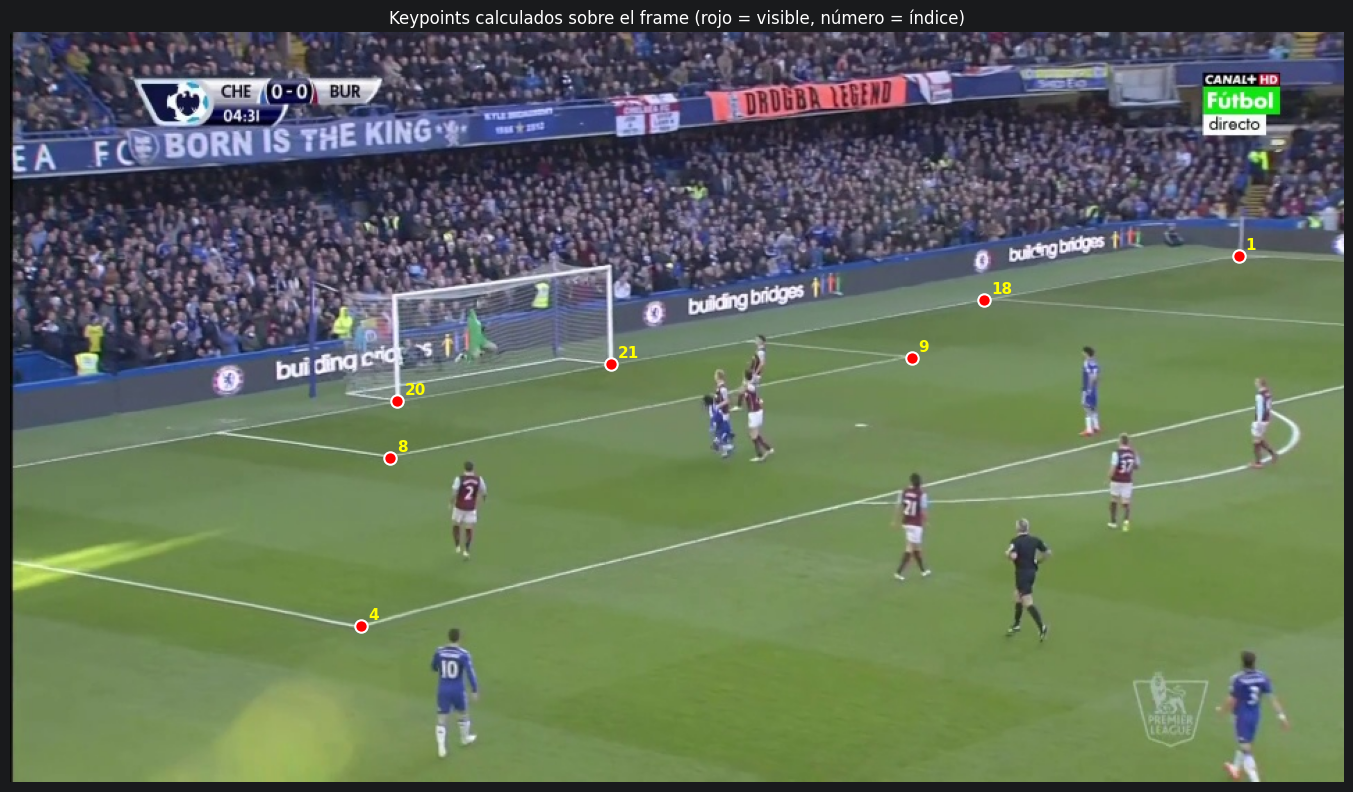

In [6]:
import matplotlib.pyplot as plt
import cv2

# Cargar la imagen correspondiente al frame de ejemplo
img_path = train_inner / "00000.jpg"
img = cv2.imread(str(img_path))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

plt.figure(figsize=(14, 8))
plt.imshow(img)

# Dibujar los keypoints visibles
for i, (x, y, v) in enumerate(kps):
    if v == 2:
        px, py = x * w, y * h
        plt.scatter(px, py, c="red", s=80, edgecolors="white", linewidths=1.5, zorder=3)
        plt.annotate(f"{i}", (px, py), color="yellow", fontsize=11,
                     fontweight="bold", xytext=(5, 5), textcoords="offset points")

plt.title("Keypoints calculados sobre el frame (rojo = visible, número = índice)")
plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Generación del dataset completo en formato YOLOv8-pose

Se procesan todos los frames de train, valid y test, generando para cada uno un archivo de etiqueta `.txt` en formato YOLOv8-pose.

El formato de cada línea es:
`class_id x_center y_center width height kp1_x kp1_y kp1_v kp2_x kp2_y kp2_v ...`

Como el campo es un único objeto que ocupa todo el frame, se usa un bounding box que cubre toda la imagen (0.5 0.5 1.0 1.0) y a continuación los 24 keypoints con su visibilidad.

In [8]:
import shutil

def procesar_split(split_name):
    inner_dir = SOCCERNET_DIR / split_name / split_name
    out_img_dir = OUTPUT_DIR / split_name / "images"
    out_lbl_dir = OUTPUT_DIR / split_name / "labels"
    out_img_dir.mkdir(parents=True, exist_ok=True)
    out_lbl_dir.mkdir(parents=True, exist_ok=True)

    json_files = sorted(inner_dir.glob("*.json"))
    procesados = 0
    descartados = 0

    for json_path in json_files:
        img_path = json_path.with_suffix(".jpg")
        if not img_path.exists():
            continue

        with open(json_path) as f:
            anot = json.load(f)

        kps = generar_keypoints_frame(anot)
        n_visibles = sum(1 for k in kps if k[2] == 2)

        # Descartar frames con menos de 4 keypoints visibles (insuficientes para homografía)
        if n_visibles < 4:
            descartados += 1
            continue

        # Construir la línea de etiqueta YOLO-pose
        # bbox que cubre toda la imagen + keypoints
        partes = ["0", "0.5", "0.5", "1.0", "1.0"]
        for (x, y, v) in kps:
            partes.extend([f"{x:.6f}", f"{y:.6f}", str(v)])
        linea = " ".join(partes)

        # Guardar imagen y etiqueta
        shutil.copy2(img_path, out_img_dir / img_path.name)
        with open(out_lbl_dir / (json_path.stem + ".txt"), "w") as f:
            f.write(linea + "\n")

        procesados += 1

    return procesados, descartados

for split in ["train", "valid", "test"]:
    proc, desc = procesar_split(split)
    print(f"{split}: {proc} procesados, {desc} descartados (menos de 4 keypoints)")

print("\nGeneración completada")

train: 10696 procesados, 5767 descartados (menos de 4 keypoints)
valid: 2000 procesados, 1212 descartados (menos de 4 keypoints)
test: 1933 procesados, 1208 descartados (menos de 4 keypoints)

Generación completada


## 6. Creación del data.yaml para YOLOv8-pose

El archivo de configuración para entrenar un modelo de pose debe especificar el número de keypoints y la forma del esqueleto.

In [9]:
nombres_kp = [nombre for nombre, _ in KEYPOINTS]

yaml_content = f"""train: {OUTPUT_DIR}/train/images
val: {OUTPUT_DIR}/valid/images
test: {OUTPUT_DIR}/test/images

kpt_shape: [{N_KEYPOINTS}, 3]
nc: 1
names: ['field']

# Nombres de los keypoints (referencia):
# {nombres_kp}
"""

yaml_path = OUTPUT_DIR / "data.yaml"
with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("data.yaml creado:\n")
print(yaml_content)

data.yaml creado:

train: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo/train/images
val: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo/valid/images
test: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\soccernet_yolo/test/images

kpt_shape: [24, 3]
nc: 1
names: ['field']

# Nombres de los keypoints (referencia):
# ['corner_inf_izq', 'corner_sup_izq', 'corner_inf_der', 'corner_sup_der', 'area_grande_izq_inf', 'area_grande_izq_sup', 'area_grande_der_inf', 'area_grande_der_sup', 'area_peq_izq_inf', 'area_peq_izq_sup', 'area_peq_der_inf', 'area_peq_der_sup', 'penalti_izq', 'penalti_der', 'centro', 'media_inf', 'media_sup', 'fondo_izq_area_inf', 'fondo_izq_area_sup', 'fondo_der_area_inf', 'poste_izq_inf', 'poste_izq_sup', 'poste_der_inf', 'poste_der_sup']



In [10]:
# Verificación final
for split in ["train", "valid", "test"]:
    imgs = list((OUTPUT_DIR / split / "images").glob("*.jpg"))
    lbls = list((OUTPUT_DIR / split / "labels").glob("*.txt"))
    print(f"{split}: {len(imgs)} imágenes, {len(lbls)} etiquetas")

train: 10696 imágenes, 10696 etiquetas
valid: 2000 imágenes, 2000 etiquetas
test: 1933 imágenes, 1933 etiquetas


Etiqueta: 00000.txt
Número de valores: 77
Esperado: 5 (clase+bbox) + 72 (keypoints) = 77

Clase: 0
BBox: ['0.5', '0.5', '1.0', '1.0']

Primeros 3 keypoints (x, y, v):
  KP0: (0.000000, 0.000000, v=0)
  KP1: (0.920896, 0.298031, v=2)
  KP2: (0.000000, 0.000000, v=0)


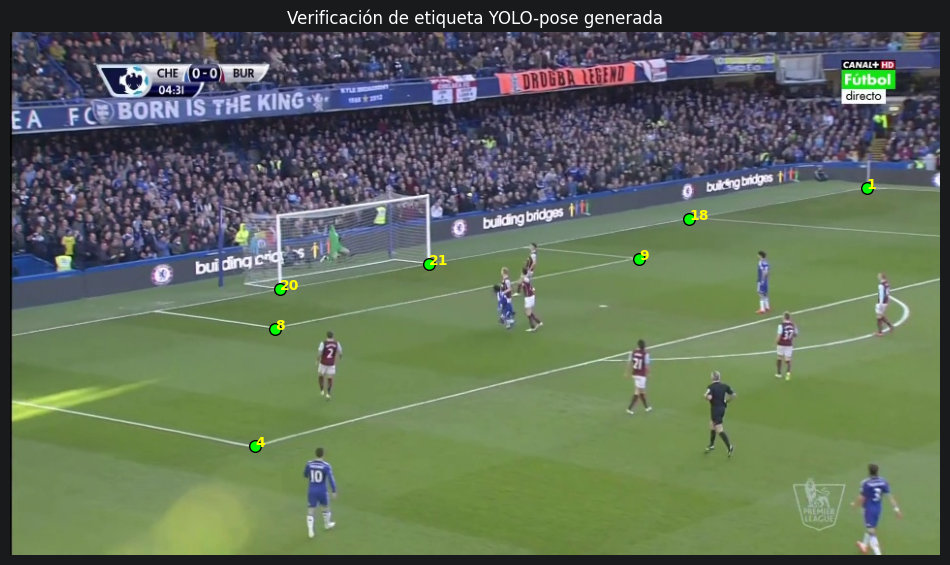

In [11]:
# Verificar una etiqueta generada
ejemplo_lbl = sorted((OUTPUT_DIR / "train" / "labels").glob("*.txt"))[0]
ejemplo_img = (OUTPUT_DIR / "train" / "images") / (ejemplo_lbl.stem + ".jpg")

with open(ejemplo_lbl) as f:
    contenido = f.read().strip()

valores = contenido.split()
print(f"Etiqueta: {ejemplo_lbl.name}")
print(f"Número de valores: {len(valores)}")
print(f"Esperado: 5 (clase+bbox) + {N_KEYPOINTS*3} (keypoints) = {5 + N_KEYPOINTS*3}\n")

print(f"Clase: {valores[0]}")
print(f"BBox: {valores[1:5]}")
print(f"\nPrimeros 3 keypoints (x, y, v):")
kps_vals = valores[5:]
for i in range(3):
    x, y, v = kps_vals[i*3:i*3+3]
    print(f"  KP{i}: ({x}, {y}, v={v})")

# Dibujar para confirmar
import matplotlib.pyplot as plt
import cv2

img = cv2.cvtColor(cv2.imread(str(ejemplo_img)), cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]
plt.figure(figsize=(12, 7))
plt.imshow(img)
for i in range(N_KEYPOINTS):
    x, y, v = kps_vals[i*3:i*3+3]
    if int(v) == 2:
        plt.scatter(float(x)*w, float(y)*h, c="lime", s=70, edgecolors="black", zorder=3)
        plt.annotate(f"{i}", (float(x)*w, float(y)*h), color="yellow", fontsize=10, fontweight="bold")
plt.title("Verificación de etiqueta YOLO-pose generada")
plt.axis("off")
plt.show()